# Wpływ wag na skuteczność rankingu `MergedRankingEvaluator`

Analiza wrażliwości połączonego rankingu anomalii na wagi trzech składników:

* `distance_weight` – model odległości międzystawowych (random forest),
* `lbp_weight` – anomalie tekstury LBP w grupach embeddingów,
* `segmentation_weight` – odległość keypointów od maski segmentacyjnej (`yolo26l-seg`).

**Zbiór i ścieżki są identyczne jak w `Preparing_datasets_for_training.ipynb`** (zbiór `final_augmented_dataset_brudny`,
raporty referencyjne `part_1_angle_preserving_out`, `part_2_rigid_out`, `part_3_axis_out`).

**Skuteczność** na wykresach i w podsumowaniu to `liczba rekordów referencyjnych danego zbioru wykrytych w top-k /
liczba rekordów referencyjnych tego zbioru` (kolumna `recall`): mianownik to 150 dla `angle_preserving`, `rigid`
i `axis_aligned` oraz 450 dla `merged`. W CSV i tabelach jest też kolumna `precision = wykryte / top-k`
(dla `merged` przy top-k = 450 obie są identyczne, dla pojedynczych zbiorów `precision` ma pułap 150/450 ≈ 0.333).

**Koszt obliczeń.** Ciężki etap (`_prepare`: trening modelu odległości, embeddingi CLIP + LBP, segmentacja)
wykonywany jest **tylko raz**. `MergedRankingEvaluator.run()` przy kolejnych wywołaniach jedynie przelicza
wagi i odbudowuje ranking, więc przeszukanie całej siatki wag trwa minuty, nie godziny.

In [1]:
import os
import sys
import io
import time
import logging
import contextlib
import warnings

# Wyciszenie prob polaczenia Hugging Face w srodowisku offline (jak w notebooku zrodlowym).
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["TRANSFORMERS_OFFLINE"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"

logging.getLogger("huggingface_hub.utils._http").setLevel(logging.ERROR)
logging.getLogger("huggingface_hub.file_download").setLevel(logging.ERROR)
try:
    from huggingface_hub import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass

# Katalog "github" repozytorium (rodzic folderu scores_from_publication); fallback na sciezke bezwzgledna.
REPO_GITHUB_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
if not os.path.isdir(os.path.join(REPO_GITHUB_DIR, "pose_data_validation")):
    REPO_GITHUB_DIR = r"D:\Politechnika\Validation_skeleton_klaudiusz\Skrypty\github"
sys.path.insert(0, REPO_GITHUB_DIR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from tqdm.auto import tqdm

from pose_data_validation.datasets import YOLOPoseDataset
from pose_data_validation.validation import YPSetValidation, MergedRankingEvaluator

print("REPO_GITHUB_DIR:", REPO_GITHUB_DIR)

REPO_GITHUB_DIR: D:\Politechnika\Validation_skeleton_klaudiusz\Skrypty\github


## 1. Konfiguracja i jednorazowe przygotowanie evaluatora

Konstrukcja `MergedRankingEvaluator` jest kopią komórki z `Preparing_datasets_for_training.ipynb`.
Jedyna różnica: wywołujemy jawnie `_prepare(...)` z włączonymi **wszystkimi trzema** składnikami,
więc kosztowne przygotowanie (modele odległości, LBP, segmentacja) wykonuje się raz, przed przeszukiwaniem
siatki wag, a kolejne `run()` tylko przeliczają ranking.

In [2]:
DATASET_TRAIN_TXT = r"D:\Politechnika\Deadlift_publikacja_nr_2\Dane_do_treningu\final_augmented_dataset_brudny\train.txt"

report_paths = {
    "angle_preserving": r"D:\Politechnika\Deadlift_publikacja_nr_2\Dane_do_treningu\partitions\part_1_angle_preserving_out\results.txt",
    "rigid": r"D:\Politechnika\Deadlift_publikacja_nr_2\Dane_do_treningu\partitions\part_2_rigid_out\results.txt",
    "axis_aligned": r"D:\Politechnika\Deadlift_publikacja_nr_2\Dane_do_treningu\partitions\part_3_axis_out\results.txt",
}

BASE_TOP_K = 450                                  # top-k uzywane w publikacji (3 x 150 rekordow referencyjnych)
K_VALUES = [150, 300, 450, 600, 900]              # dodatkowe wartosci top-k liczone z tego samego rankingu
WEIGHT_STEP = 0.05                                # krok siatki wag (wagi sumuja sie do 1)
PUBLICATION_WEIGHTS = (0.65, 0.10, 0.25)          # wagi uzyte w notebooku zrodlowym (merged_450)
DEFAULT_WEIGHTS = (0.50, 0.10, 0.40)              # domyslne wagi funkcji test() w notebooku zrodlowym
REPORT_ORDER = ["merged", "angle_preserving", "rigid", "axis_aligned"]
RESULTS_CSV = "weights_sensitivity_results.csv"

dataset = YOLOPoseDataset(DATASET_TRAIN_TXT)
validator = YPSetValidation(dataset)

evaluator = MergedRankingEvaluator(
    validator=validator,
    report_paths=report_paths,
    top_k=BASE_TOP_K,
    output_path=None,
    distance_model_name="random_forest",
    distance_visibility_threshold=2.0,
    distance_threshold_percentile=95.0,
    distance_sort_by="mean",
    segmentation_mask_tolerance_px=24,
    segmentation_model_name="yolo26l-seg",
    segmentation_target_class="person",
)

prepare_start = time.perf_counter()
evaluator._prepare(include_distance=True, include_lbp=True, include_segmentation=True)
prepare_elapsed = time.perf_counter() - prepare_start

print(f"_prepare zakonczone w {prepare_elapsed:.1f} s")
print(
    f"all_samples={len(evaluator.all_samples)} | distance={evaluator.distance_total} | "
    f"lbp={evaluator.lbp_total} | mask_ranked_records={evaluator.mask_total} | "
    f"outside_persons={evaluator.outside_person_total}"
)
for name, entries in evaluator.reference_report_entries.items():
    print(f"referencja {name}: {len(entries)} rekordow")

All similarity groups: 96
Training groups with size > 10: 13
_prepare zakonczone w 313.7 s
all_samples=1919 | distance=1615 | lbp=253 | mask_ranked_records=1919 | outside_persons=175
referencja angle_preserving: 150 rekordow
referencja rigid: 150 rekordow
referencja axis_aligned: 150 rekordow
referencja merged: 450 rekordow


## 2. Kontrola zgodności z notebookiem źródłowym

Pojedyncze `run()` z wagami z publikacji (0.65 / 0.10 / 0.25). Linia `weights=... | merged=...`
powinna być identyczna z wynikiem komórki `merged_450 = test(x=450, ...)` w `Preparing_datasets_for_training.ipynb`.
Mierzymy też czas jednego `run()` – to koszt jednego punktu siatki wag.

In [3]:
run_start = time.perf_counter()
baseline_result = evaluator.run(*PUBLICATION_WEIGHTS)
run_elapsed = time.perf_counter() - run_start
print(f"\nCzas pojedynczego run() (bez ponownego _prepare): {run_elapsed:.2f} s")

weights=0.650/0.100/0.250 | merged=314/450 | overall=450/450 | avg_rank_all=432.41 | angle_preserving=99/150 | overall=150/150 | avg_rank_all=556.29 | rigid=87/150 | overall=150/150 | avg_rank_all=497.72 | axis_aligned=128/150 | overall=150/150 | avg_rank_all=243.23
CACHE READY | all_samples=1919 | distance=1615 | lbp=253 | mask_ranked_records=1919 | segmentation_with_mask=1786 | segmentation_without_mask=7 | outside=175 | outside_person_total=175 | outside_persons_in_top_k=175 | outside_mentioned_in_merged=0

Czas pojedynczego run() (bez ponownego _prepare): 0.19 s


## 3. Funkcje pomocnicze

`evaluate_weights` wywołuje `evaluator.run(...)` (z wyciszonym `print`), a następnie dla każdej wartości `top_k`
porównuje **ten sam** `combined_ranking` z każdym raportem referencyjnym metodą
`_compare_reference_entries_to_anomalies` (tak samo robią komórki MITL w notebooku źródłowym).
Dzięki temu jeden `run()` daje wyniki dla wszystkich `K_VALUES`.

In [4]:
def run_quiet(evaluator, distance_weight, lbp_weight, segmentation_weight):
    # evaluator.run drukuje dwie linie podsumowania - w petli po siatce tylko zasmiecaja output.
    with contextlib.redirect_stdout(io.StringIO()):
        return evaluator.run(
            distance_weight=distance_weight,
            lbp_weight=lbp_weight,
            segmentation_weight=segmentation_weight,
        )


def evaluate_weights(evaluator, distance_weight, lbp_weight, segmentation_weight, k_values):
    result = run_quiet(evaluator, distance_weight, lbp_weight, segmentation_weight)
    if not result:
        return []

    combined_ranking = result["combined_ranking"]
    original_top_k = evaluator.top_k
    rows = []
    try:
        for top_k in k_values:
            evaluator.top_k = int(top_k)
            for report_name, reference_entries in evaluator.reference_report_entries.items():
                comparison = evaluator._compare_reference_entries_to_anomalies(reference_entries, combined_ranking)
                matched = int(comparison["matched_top_k_count"])
                total_reference = int(comparison["total_reference_entries"])
                rows.append(
                    {
                        "distance_w": round(float(distance_weight), 4),
                        "lbp_w": round(float(lbp_weight), 4),
                        "seg_w": round(float(segmentation_weight), 4),
                        "top_k": int(top_k),
                        "report": report_name,
                        "matched_top_k": matched,
                        "total_reference": total_reference,
                        "precision": matched / float(top_k),
                        "recall": matched / float(total_reference) if total_reference else np.nan,
                        "avg_rank_all_reference": comparison["avg_rank_all_reference"],
                        "last_matched_rank_in_top_k": comparison["last_matched_rank_in_top_k"],
                    }
                )
    finally:
        evaluator.top_k = original_top_k
    return rows


def simplex_grid(step):
    # Wszystkie trojki (d, l, s) >= 0 o sumie 1 z krokiem `step`. Ranking zalezy tylko od proporcji wag,
    # bo weighted_score jest dzielone przez sume wag, wiec suma = 1 nie ogranicza ogolnosci.
    n_steps = int(round(1.0 / step))
    grid = []
    for i in range(n_steps + 1):
        for j in range(n_steps + 1 - i):
            k = n_steps - i - j
            grid.append((round(i * step, 4), round(j * step, 4), round(k * step, 4)))
    return grid


def weights_label(weights):
    return "/".join(f"{w:.2f}" for w in weights)


# --- styl wykresow: jak w Detected_not_detected_comp.ipynb (serif, pelna ramka, duze etykiety osi, bez tytulow) ---
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "axes.linewidth": 1.0,
    }
)
AXIS_LABEL_SIZE = 17
TICK_LABEL_SIZE = 13
LEGEND_SIZE = 13
EFFICIENCY_LABEL = "Efficiency (detected / reference)"
# Zielony i czerwony jak w notebooku referencyjnym, trzeci kolor (niebieski) w tej samej tonacji.
SERIES = {"distance": "#2E8B57", "lbp": "#C0392B", "segmentation": "#2874A6"}
MARKERS = {"distance": "o", "lbp": "s", "segmentation": "^"}
COMPONENT_LABELS = {"distance": "Distance", "lbp": "LBP", "segmentation": "Segmentation"}
SEQUENTIAL_CMAP = plt.get_cmap("RdYlGn").copy()    # czerwony = niska skutecznosc, zielony = wysoka
SEQUENTIAL_CMAP.set_bad("white")
BEST_MARKER = dict(marker="*", markersize=16, color="#F1C40F", markeredgecolor="black", markeredgewidth=0.9,
                   linestyle="none")
PUBLICATION_MARKER = dict(marker="o", markersize=10, markerfacecolor="white", markeredgecolor="black",
                          markeredgewidth=1.5, linestyle="none")


def style_axes(ax, xlabel=None, ylabel=None, grid_axis="y"):
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=AXIS_LABEL_SIZE)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=AXIS_LABEL_SIZE)
    ax.tick_params(axis="both", labelsize=TICK_LABEL_SIZE)
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle="--", linewidth=0.6, alpha=0.5)


def style_legend(ax, **kwargs):
    options = dict(fontsize=LEGEND_SIZE, frameon=True, edgecolor="black")
    options.update(kwargs)
    return ax.legend(**options)


def style_colorbar(colorbar, label):
    colorbar.set_label(label, fontsize=AXIS_LABEL_SIZE - 2)
    colorbar.ax.tick_params(labelsize=TICK_LABEL_SIZE)
    colorbar.outline.set_linewidth(1.0)


print("Liczba punktow siatki wag:", len(simplex_grid(WEIGHT_STEP)))

Liczba punktow siatki wag: 231


## 4. Przeszukanie siatki wag

Każdy punkt siatki to jedno `run()` (tylko przeliczenie wag i rankingu). Wyniki w formacie długim
(`report × top_k × wagi`) zapisujemy do CSV obok notebooka.

In [5]:
weight_grid = simplex_grid(WEIGHT_STEP)
# Dodajemy wagi z publikacji i domyslne, jesli nie leza na siatce.
for extra in (PUBLICATION_WEIGHTS, DEFAULT_WEIGHTS):
    if tuple(round(w, 4) for w in extra) not in weight_grid:
        weight_grid.append(tuple(round(w, 4) for w in extra))

sweep_start = time.perf_counter()
all_rows = []
for distance_w, lbp_w, seg_w in tqdm(weight_grid, desc="Siatka wag"):
    all_rows.extend(evaluate_weights(evaluator, distance_w, lbp_w, seg_w, K_VALUES))
sweep_elapsed = time.perf_counter() - sweep_start

df = pd.DataFrame(all_rows)
df["report"] = pd.Categorical(df["report"], categories=REPORT_ORDER, ordered=True)
df["weights"] = df.apply(lambda r: weights_label((r["distance_w"], r["lbp_w"], r["seg_w"])), axis=1)
df.to_csv(RESULTS_CSV, index=False)

print(f"Przeliczono {len(weight_grid)} kombinacji wag x {len(K_VALUES)} top-k w {sweep_elapsed:.1f} s "
      f"({sweep_elapsed / len(weight_grid):.2f} s / kombinacje). Zapisano: {RESULTS_CSV}")
df.head(8)

Przeliczono 231 kombinacji wag x 5 top-k w 237.8 s (1.03 s / kombinacje). Zapisano: weights_sensitivity_results.csv


,distance_w,lbp_w,seg_w,top_k,report,matched_top_k,total_reference,precision,recall,avg_rank_all_reference,last_matched_rank_in_top_k,weights
0,0.0,0.0,1.0,150,angle_preserving,6,150,0.040000,0.040000,866.706667,150,0.00/0.00/1.00
1,0.0,0.0,1.0,150,rigid,65,150,0.433333,0.433333,359.666667,143,0.00/0.00/1.00
2,0.0,0.0,1.0,150,axis_aligned,78,150,0.520000,0.520000,288.753333,149,0.00/0.00/1.00
3,0.0,0.0,1.0,150,merged,149,450,0.993333,0.331111,505.042222,150,0.00/0.00/1.00
4,0.0,0.0,1.0,300,angle_preserving,10,150,0.033333,0.066667,866.706667,217,0.00/0.00/1.00
5,0.0,0.0,1.0,300,rigid,108,150,0.360000,0.720000,359.666667,295,0.00/0.00/1.00
6,0.0,0.0,1.0,300,axis_aligned,116,150,0.386667,0.773333,288.753333,292,0.00/0.00/1.00
7,0.0,0.0,1.0,300,merged,234,450,0.780000,0.520000,505.042222,295,0.00/0.00/1.00


## 5. Punkty odniesienia: pojedyncze modele, równe wagi, wagi z publikacji (top-k = 450)

`recall` to skuteczność `wykryte / 150` (lub `/450` dla `merged`); `precision` to `wykryte / top-k`.

> **Uwaga o segmentacji.** Niezależnie od wag `_build_combined_ranking` zawsze wypycha na początek rankingu
> osoby, których widoczne keypointy leżą poza maską (`promoted_outside_mask`). Ta część top-k jest więc
> stała, a wagi rozstrzygają o pozostałych pozycjach. Dlatego nawet przy `segmentation_weight = 0`
> segmentacja wpływa na wynik.

In [6]:
reference_configs = {
    "tylko distance (1/0/0)": (1.0, 0.0, 0.0),
    "tylko lbp (0/1/0)": (0.0, 1.0, 0.0),
    "tylko segmentation (0/0/1)": (0.0, 0.0, 1.0),
    "rowne wagi (1/3 kazda)": (1 / 3, 1 / 3, 1 / 3),
    f"domyslne test() ({weights_label(DEFAULT_WEIGHTS)})": DEFAULT_WEIGHTS,
    f"publikacja ({weights_label(PUBLICATION_WEIGHTS)})": PUBLICATION_WEIGHTS,
}

reference_rows = []
for config_name, weights in reference_configs.items():
    for row in evaluate_weights(evaluator, *weights, [BASE_TOP_K]):
        row["config"] = config_name
        reference_rows.append(row)
reference_df = pd.DataFrame(reference_rows)

reference_table = reference_df.pivot_table(
    index="config", columns="report", values=["matched_top_k", "precision", "recall"], observed=False
).reindex(list(reference_configs.keys()))
reference_table = reference_table.reindex(columns=REPORT_ORDER, level=1)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 260)
print(f"top_k = {BASE_TOP_K}; liczba osob stale promowanych (poza maska): {evaluator.outside_person_total}")
reference_table.round(3)

top_k = 450; liczba osob stale promowanych (poza maska): 175


matched_top_k                                      precision                                      recall                                     
report                                  merged angle_preserving  rigid axis_aligned    merged angle_preserving  rigid axis_aligned merged angle_preserving  rigid axis_aligned
config                                                                                                                                                                        
tylko distance (1/0/0)                   304.0            101.0   75.0        128.0     0.676            0.224  0.167        0.284  0.676            0.673  0.500        0.853
tylko lbp (0/1/0)                        216.0             27.0   86.0        103.0     0.480            0.060  0.191        0.229  0.480            0.180  0.573        0.687
tylko segmentation (0/0/1)               276.0             27.0  124.0        125.0     0.613            0.060  0.276        0.278  0.613            0.180  0.827        0.833
rowne wagi (1/3 kazda)                   305.0             66.0  114.0        125.0     0.678            0.147  0.253        0.278  0.678            0.440  0.760        0.833
domyslne test() (0.50/0.10/0.40)         308.0             78.0  104.0        126.0     0.684            0.173  0.231        0.280  0.684            0.520  0.693        0.840
publikacja (0.65/0.10/0.25)              314.0             99.0   87.0        128.0     0.698            0.220  0.193        0.284  0.698            0.660  0.580        0.853

## 6. Najlepsze kombinacje wag dla każdego zbioru (top-k = 450)

Dla każdego raportu wybieramy 10 najlepszych punktów siatki wg skuteczności `recall` (remisy rozstrzyga `avg_rank_all_reference`,
czyli średnia pozycja wszystkich rekordów referencyjnych w pełnym rankingu – im niższa, tym lepiej).

In [7]:
df_k = df[df["top_k"] == BASE_TOP_K].copy()

best_per_report = {}
for report_name in REPORT_ORDER:
    subset = df_k[df_k["report"] == report_name].sort_values(
        ["recall", "avg_rank_all_reference"], ascending=[False, True]
    )
    best_per_report[report_name] = subset.iloc[0]
    print(f"\n=== {report_name} | top-10 wg skutecznosci (wykryte / ref.) przy top-k={BASE_TOP_K} ===")
    print(
        subset.head(10)[["weights", "distance_w", "lbp_w", "seg_w", "matched_top_k", "total_reference",
                         "recall", "precision", "avg_rank_all_reference"]]
        .to_string(index=False, float_format=lambda v: f"{v:.3f}")
    )

best_merged = best_per_report["merged"]
BEST_WEIGHTS = (float(best_merged["distance_w"]), float(best_merged["lbp_w"]), float(best_merged["seg_w"]))
publication_merged = df_k[(df_k["report"] == "merged") & (df_k["weights"] == weights_label(PUBLICATION_WEIGHTS))].iloc[0]
print(
    f"\nNajlepsze wagi dla merged: {weights_label(BEST_WEIGHTS)} -> "
    f"{int(best_merged['matched_top_k'])}/{int(best_merged['total_reference'])} = {best_merged['recall']:.3f}; "
    f"publikacja {weights_label(PUBLICATION_WEIGHTS)} -> "
    f"{int(publication_merged['matched_top_k'])}/{int(publication_merged['total_reference'])} = {publication_merged['recall']:.3f}"
)


=== merged | top-10 wg skutecznosci (wykryte / ref.) przy top-k=450 ===
       weights  distance_w  lbp_w  seg_w  matched_top_k  total_reference  recall  precision  avg_rank_all_reference
0.15/0.80/0.05       0.150  0.800  0.050            316              450   0.702      0.702                 436.764
0.30/0.60/0.10       0.300  0.600  0.100            316              450   0.702      0.702                 436.956
0.60/0.15/0.25       0.600  0.150  0.250            315              450   0.700      0.700                 430.002
0.40/0.45/0.15       0.400  0.450  0.150            315              450   0.700      0.700                 433.164
0.55/0.25/0.20       0.550  0.250  0.200            315              450   0.700      0.700                 434.187
0.70/0.00/0.30       0.700  0.000  0.300            314              450   0.698      0.698                 429.109
0.25/0.65/0.10       0.250  0.650  0.100            314              450   0.698      0.698                 431.016

## 7. Mapy skuteczności na sympleksie wag

Oś X: `distance_weight`, oś Y: `lbp_weight`; `segmentation_weight = 1 − distance − lbp` (przekątna to brak segmentacji
w wagach). Gwiazdka – najlepszy punkt dla danego zbioru, kółko – wagi z publikacji. Kolor to skuteczność
`wykryte / liczba rekordów referencyjnych zbioru` (150, dla `merged` 450); osobny wykres i skala dla każdego zbioru.
Styl wykresów jak w `Detected_not_detected_comp.ipynb` (serif, pełna ramka, bez tytułów; zbiór podany w linii nad wykresem).

merged: max 0.702 (316/450) przy wagach 0.15/0.80/0.05; segmentation_weight = 1 - distance - lbp


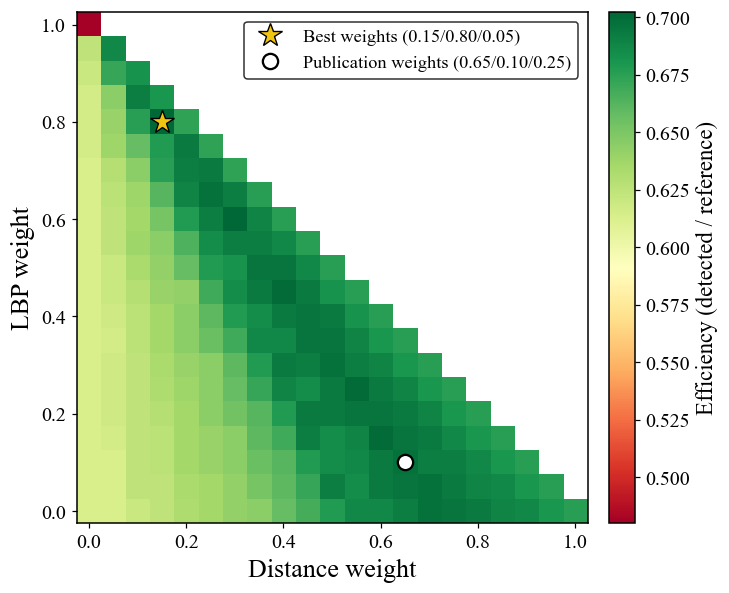

angle_preserving: max 0.707 (106/150) przy wagach 0.65/0.20/0.15; segmentation_weight = 1 - distance - lbp


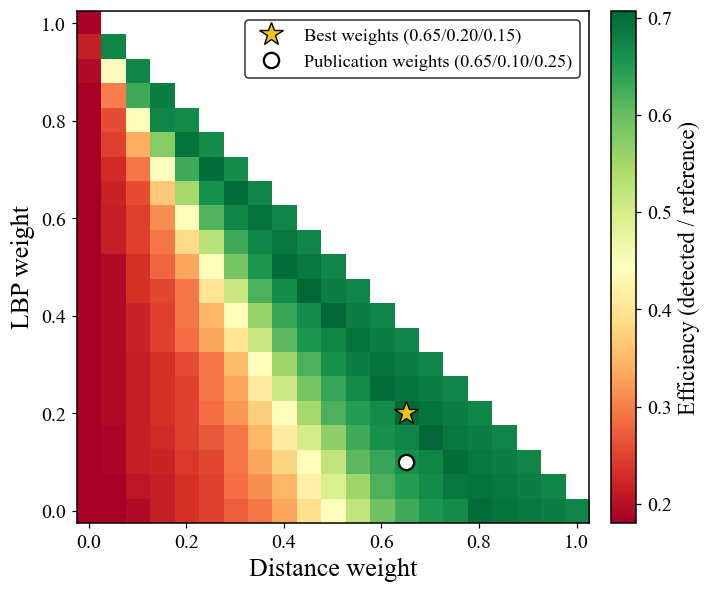

rigid: max 0.833 (125/150) przy wagach 0.00/0.90/0.10; segmentation_weight = 1 - distance - lbp


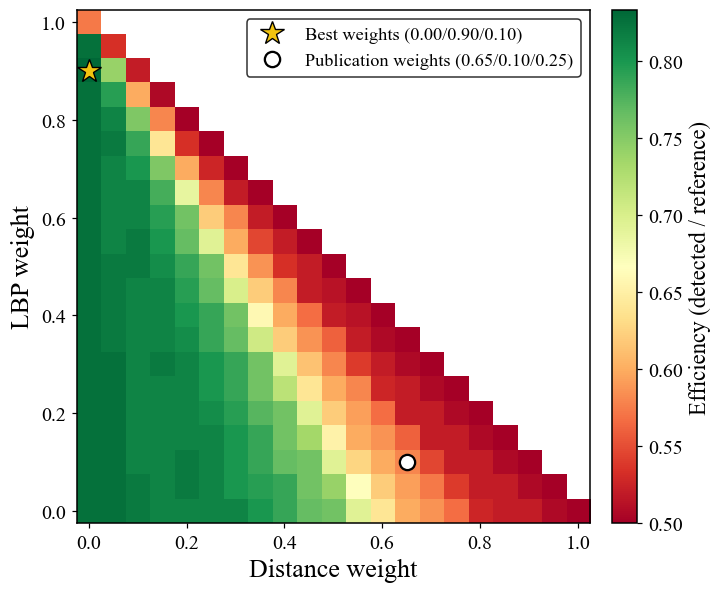

axis_aligned: max 0.853 (128/150) przy wagach 0.70/0.00/0.30; segmentation_weight = 1 - distance - lbp


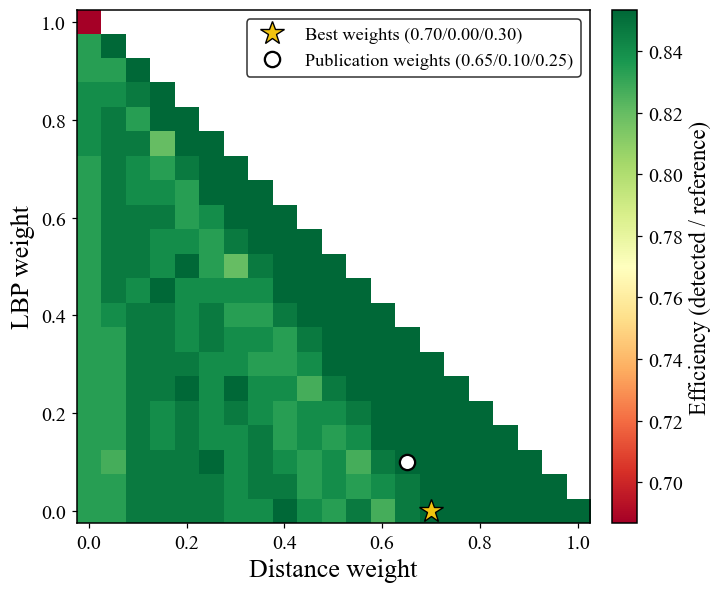

In [8]:
def plot_simplex_heatmap(ax, subset, best, publication):
    values = np.sort(subset["distance_w"].unique())
    index = {v: i for i, v in enumerate(values)}
    matrix = np.full((len(values), len(values)), np.nan)
    for _, row in subset.iterrows():
        if row["distance_w"] in index and row["lbp_w"] in index:
            matrix[index[row["lbp_w"]], index[row["distance_w"]]] = row["recall"]

    image = ax.imshow(matrix, origin="lower", cmap=SEQUENTIAL_CMAP, aspect="equal",
                      extent=[-WEIGHT_STEP / 2, 1 + WEIGHT_STEP / 2, -WEIGHT_STEP / 2, 1 + WEIGHT_STEP / 2])
    ax.plot([best["distance_w"]], [best["lbp_w"]], label=f"Best weights ({best['weights']})", **BEST_MARKER)
    ax.plot([publication[0]], [publication[1]], label=f"Publication weights ({weights_label(publication)})",
            **PUBLICATION_MARKER)
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    style_axes(ax, "Distance weight", "LBP weight", grid_axis=None)
    style_legend(ax, loc="upper right", fontsize=12)
    colorbar = plt.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
    style_colorbar(colorbar, EFFICIENCY_LABEL)


grid_only = df_k[df_k["weights"].isin({weights_label(w) for w in simplex_grid(WEIGHT_STEP)})]
for report_name in REPORT_ORDER:
    best = best_per_report[report_name]
    print(f"{report_name}: max {best['recall']:.3f} ({int(best['matched_top_k'])}/{int(best['total_reference'])}) "
          f"przy wagach {best['weights']}; segmentation_weight = 1 - distance - lbp")
    fig, ax = plt.subplots(1, 1, figsize=(7.5, 5.5), tight_layout=True)
    plot_simplex_heatmap(ax, grid_only[grid_only["report"] == report_name], best, PUBLICATION_WEIGHTS)
    plt.show()

## 7b. Wykresy ternarne dla trzech zbiorów

Ta sama informacja co na mapach wyżej, ale w naturalnych współrzędnych sympleksu: każdy punkt trójkąta to jedna
kombinacja wag (`distance + lbp + segmentation = 1`), narożniki odpowiadają pojedynczym modelom.
Powierzchnia to interpolacja skuteczności `wykryte / 150` między punktami siatki (kropki), gwiazdka – najlepsza kombinacja
dla danego zbioru. Kolor od czerwonego (niska skuteczność) do zielonego (wysoka). Linie pomocnicze co 0.2 wagi.
Od lewej: `angle_preserving`, `rigid`, `axis_aligned`.

angle_preserving: max 0.707 (106/150) przy wagach 0.65/0.20/0.15
rigid: max 0.833 (125/150) przy wagach 0.00/0.90/0.10
axis_aligned: max 0.853 (128/150) przy wagach 0.70/0.00/0.30
Wspolna skala: 0.15 - 0.90 (krok 0.05)


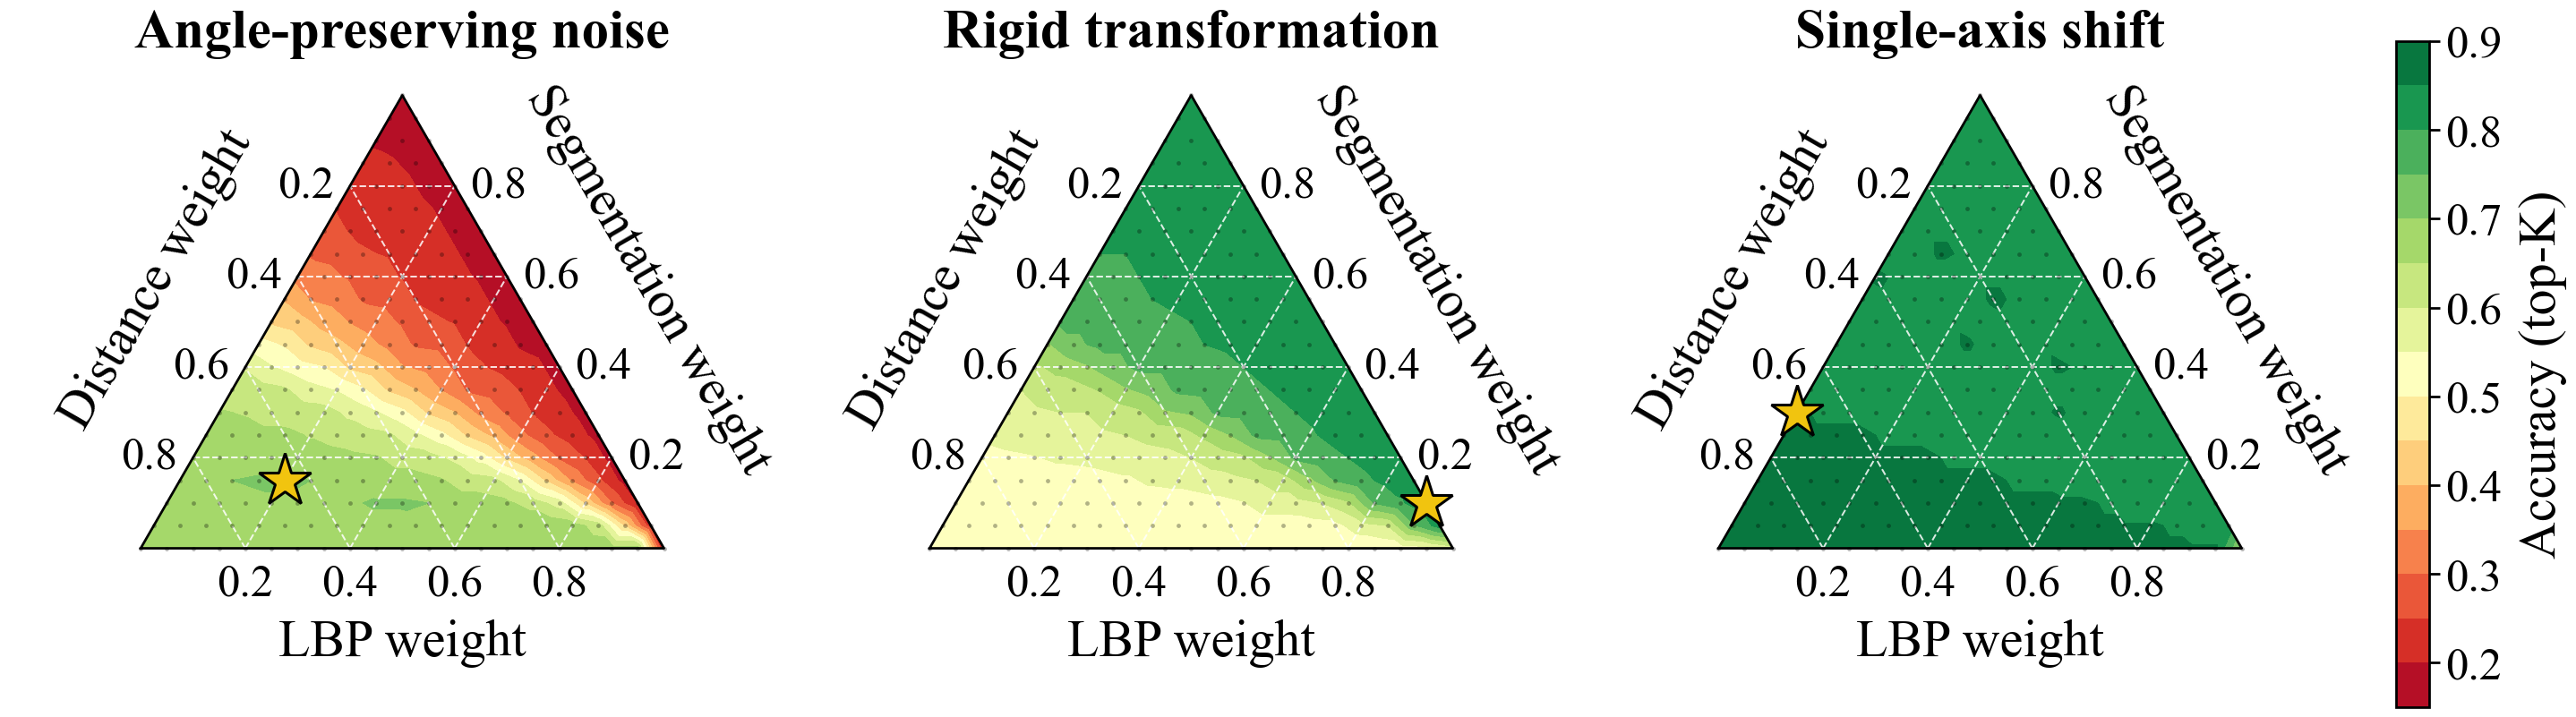

In [12]:
import matplotlib.tri as mtri

# Rozmiary opisow na wykresach ternarnych. Figura ma 26 cali szerokosci, a w publikacji zostanie zmniejszona
# do szerokosci strony (~7 cali, skala ~0.27), wiec czcionki sa ~3.5x wieksze niz docelowe 9-11 pt.
TERNARY_TICK_SIZE = 33
TERNARY_AXIS_SIZE = 38
TERNARY_TITLE_SIZE = 40
TERNARY_LINE_WIDTH = 1.8                     # obrys trojkata
TERNARY_GRID_WIDTH = 1.3                     # biale linie pomocnicze co 0.2
# Gwiazdka najlepszych wag: ten sam styl co na mapach, ale ~2.5x wieksza (inaczej znika po zmniejszeniu figury).
TERNARY_BEST_MARKER = {**BEST_MARKER, "markersize": 40, "markeredgewidth": 2.0}

TERNARY_CORNERS = {
    "distance": np.array([0.0, 0.0]),
    "lbp": np.array([1.0, 0.0]),
    "segmentation": np.array([0.5, np.sqrt(3) / 2]),
}


def ternary_xy(distance_w, lbp_w, seg_w):
    # Wspolrzedne barycentryczne -> 2D: distance w lewym dolnym rogu, lbp w prawym dolnym, segmentation na gorze.
    distance_w, lbp_w, seg_w = (np.asarray(v, dtype=float) for v in (distance_w, lbp_w, seg_w))
    x = lbp_w + 0.5 * seg_w
    y = seg_w * np.sqrt(3) / 2
    return x, y


def draw_ternary_frame(ax, tick_step=0.2):
    corners = np.array([TERNARY_CORNERS["distance"], TERNARY_CORNERS["lbp"], TERNARY_CORNERS["segmentation"],
                        TERNARY_CORNERS["distance"]])
    ax.plot(corners[:, 0], corners[:, 1], color="black", linewidth=TERNARY_LINE_WIDTH, zorder=3)
    for value in np.arange(tick_step, 1.0, tick_step):
        rest = 1.0 - value
        segments = [
            (ternary_xy(value, rest, 0.0), ternary_xy(value, 0.0, rest)),   # distance = value
            (ternary_xy(rest, value, 0.0), ternary_xy(0.0, value, rest)),   # lbp = value
            (ternary_xy(rest, 0.0, value), ternary_xy(0.0, rest, value)),   # segmentation = value
        ]
        for (x0, y0), (x1, y1) in segments:
            ax.plot([x0, x1], [y0, y1], color="white", linewidth=TERNARY_GRID_WIDTH, linestyle="--", alpha=0.85,
                    zorder=2)
        # Kazda krawedz opisuje jedna skladowa: dol = lbp (rosnie w prawo), lewa = distance (rosnie w dol),
        # prawa = segmentation (rosnie ku gorze).
        x, y = ternary_xy(rest, value, 0.0)
        ax.text(x, y - 0.03, f"{value:.1f}", ha="center", va="top", fontsize=TERNARY_TICK_SIZE)
        x, y = ternary_xy(0.0, rest, value)
        ax.text(x + 0.03, y, f"{value:.1f}", ha="left", va="center", fontsize=TERNARY_TICK_SIZE)
        x, y = ternary_xy(value, 0.0, rest)
        ax.text(x - 0.03, y, f"{value:.1f}", ha="right", va="center", fontsize=TERNARY_TICK_SIZE)

    # Tytuly krawedzi (bez strzalek i bez podpisow wierzcholkow): dolna pod etykietami 0.2-0.8, boczne w srodku
    # krawedzi przesuniete o `side_offset` wzdluz normalnej na zewnatrz trojkata.
    ax.text(0.5, -0.135, "LBP weight", ha="center", va="top", fontsize=TERNARY_AXIS_SIZE)
    side_pos, side_offset = 0.46, 0.23
    x, y = 0.5 * side_pos - side_offset * np.sqrt(3) / 2, side_pos * np.sqrt(3) / 2 + side_offset / 2
    ax.text(x, y, "Distance weight", rotation=60, ha="center", va="center", fontsize=TERNARY_AXIS_SIZE)
    x, y = 1.0 - 0.5 * side_pos + side_offset * np.sqrt(3) / 2, side_pos * np.sqrt(3) / 2 + side_offset / 2
    ax.text(x, y, "Segmentation weight", rotation=-60, ha="center", va="center", fontsize=TERNARY_AXIS_SIZE)

    ax.set_xlim(-0.25, 1.25)
    ax.set_ylim(-0.27, np.sqrt(3) / 2 + 0.07)
    ax.set_aspect("equal")
    ax.axis("off")


def plot_ternary(ax, subset, best, levels):
    x, y = ternary_xy(subset["distance_w"].values, subset["lbp_w"].values, subset["seg_w"].values)
    triangulation = mtri.Triangulation(x, y)
    filled = ax.tricontourf(triangulation, subset["recall"].values, levels=levels, cmap=SEQUENTIAL_CMAP,
                            vmin=levels[0], vmax=levels[-1], zorder=1)
    ax.scatter(x, y, s=10, color="black", alpha=0.3, linewidths=0, zorder=4)
    draw_ternary_frame(ax)

    bx, by = ternary_xy(best["distance_w"], best["lbp_w"], best["seg_w"])
    ax.plot([bx], [by], zorder=6, clip_on=False, **TERNARY_BEST_MARKER)   # gwiazdka = najlepsze wagi (bez legendy)
    return filled


# Trzy zbiory obok siebie na jednym obrazku (kolejnosc od lewej: angle_preserving, rigid, axis_aligned).
TERNARY_REPORTS = ["angle_preserving", "rigid", "axis_aligned"]
for report_name in TERNARY_REPORTS:
    best = best_per_report[report_name]
    print(f"{report_name}: max {best['recall']:.3f} ({int(best['matched_top_k'])}/{int(best['total_reference'])}) "
          f"przy wagach {best['weights']}")

# Wspolna skala kolorow dla wszystkich trzech zbiorow: zakres = min/max skutecznosci po trzech zbiorach,
# zaokraglony do 0.05, poziomy co 0.05. Ten sam kolor oznacza wiec te sama skutecznosc na kazdym trojkacie.
ternary_values = grid_only[grid_only["report"].isin(TERNARY_REPORTS)]["recall"]
TERNARY_LEVEL_STEP = 0.05
ternary_vmin = np.floor(ternary_values.min() / TERNARY_LEVEL_STEP) * TERNARY_LEVEL_STEP
ternary_vmax = np.ceil(ternary_values.max() / TERNARY_LEVEL_STEP) * TERNARY_LEVEL_STEP
ternary_levels = np.round(np.arange(ternary_vmin, ternary_vmax + TERNARY_LEVEL_STEP / 2, TERNARY_LEVEL_STEP), 4)
print(f"Wspolna skala: {ternary_levels[0]:.2f} - {ternary_levels[-1]:.2f} (krok {TERNARY_LEVEL_STEP})")

# Rodzaj szumu podpisany nad kazdym trojkatem i opis paska kolorow (nazwy jak w tekscie publikacji).
TERNARY_COLORBAR_LABEL = "Accuracy (top-K)"
NOISE_TYPE_LABELS = {
    "angle_preserving": "Angle-preserving noise",
    "rigid": "Rigid transformation",
    "axis_aligned": "Single-axis shift",
}

fig, axes = plt.subplots(1, 3, figsize=(26, 7.6), layout="constrained")
fig.get_layout_engine().set(w_pad=0.02, wspace=0.0)
for ax, report_name in zip(axes, TERNARY_REPORTS):
    filled = plot_ternary(ax, grid_only[grid_only["report"] == report_name], best_per_report[report_name],
                          ternary_levels)
    ax.set_title(NOISE_TYPE_LABELS[report_name], fontsize=TERNARY_TITLE_SIZE, fontweight="bold", pad=4)
colorbar_ticks = [level for level in ternary_levels if abs(level * 10 - round(level * 10)) < 1e-6]   # 0.2, 0.3, ...
colorbar = fig.colorbar(filled, ax=list(axes), fraction=0.025, pad=0.01, shrink=0.9, ticks=colorbar_ticks)
colorbar.set_label(TERNARY_COLORBAR_LABEL, fontsize=TERNARY_AXIS_SIZE, labelpad=12)
colorbar.ax.tick_params(labelsize=TERNARY_TICK_SIZE, width=TERNARY_LINE_WIDTH, length=8)
colorbar.outline.set_linewidth(TERNARY_LINE_WIDTH)
plt.show()

## 8. Profile brzegowe: skuteczność w funkcji pojedynczej wagi

Dla każdej wartości wagi jednego składnika bierzemy **maksimum** (linia ciągła) i **średnią** (linia kropkowana)
skuteczności (`wykryte / ref.`, top-k = 450) po wszystkich punktach siatki z tą wagą. Maksimum mówi, czy daną wartość da się „uratować”
pozostałymi wagami; średnia – jak ryzykowna jest ta wartość przeciętnie.

merged


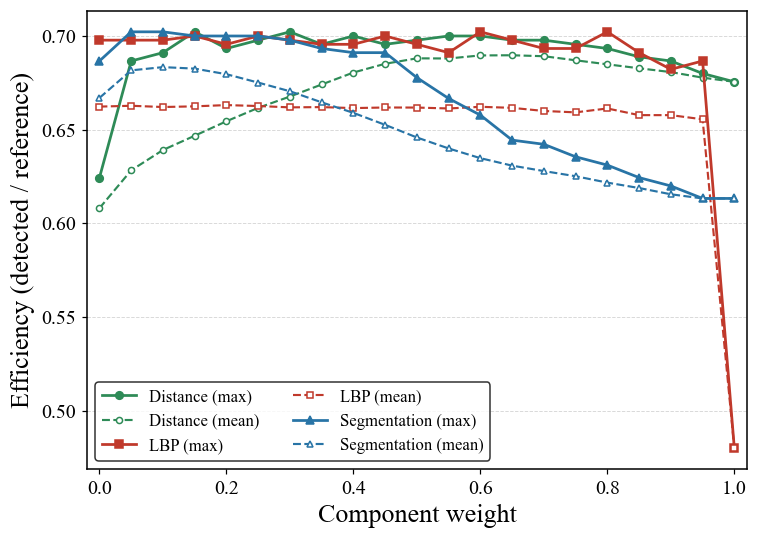

angle_preserving


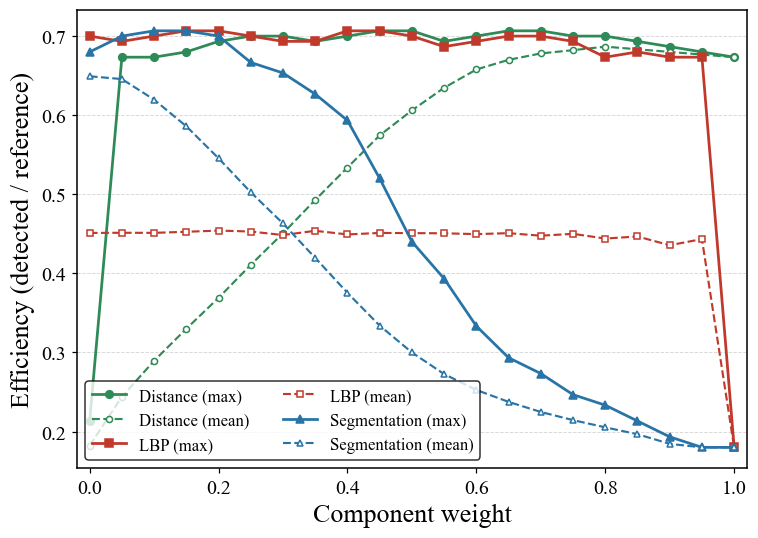

rigid


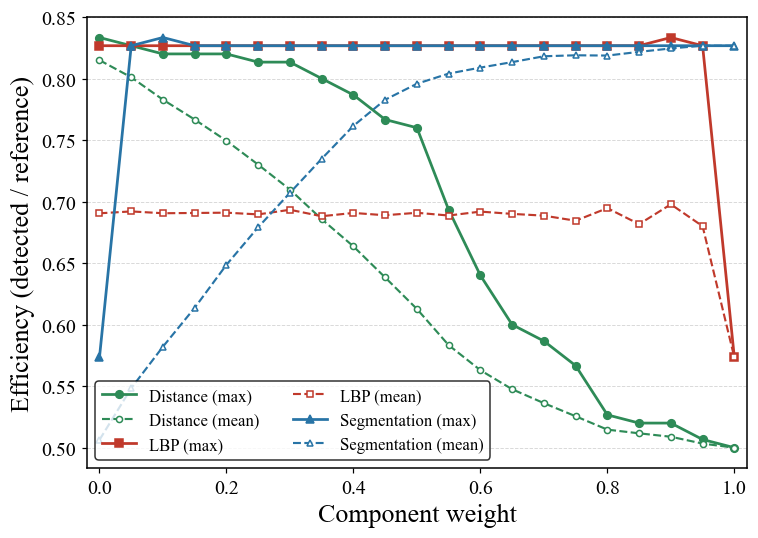

axis_aligned


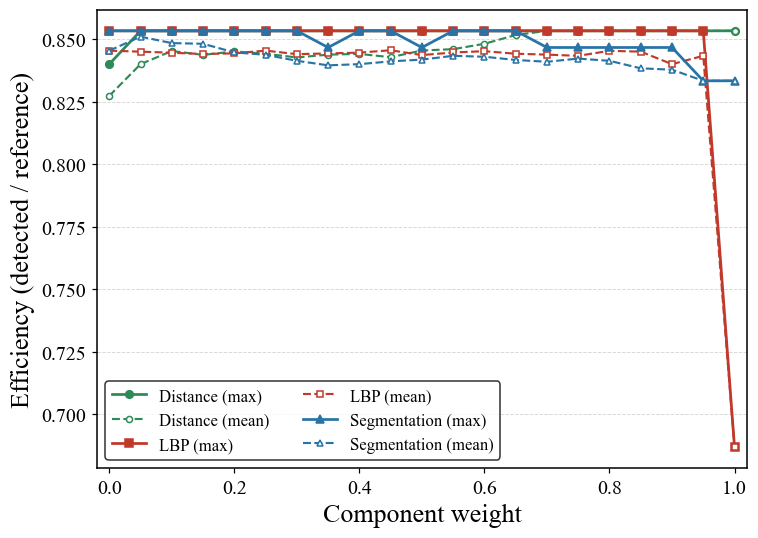

In [9]:
component_columns = {"distance": "distance_w", "lbp": "lbp_w", "segmentation": "seg_w"}

for report_name in REPORT_ORDER:
    print(report_name)
    subset = grid_only[grid_only["report"] == report_name]
    fig, ax = plt.subplots(1, 1, figsize=(7, 5), tight_layout=True)
    for component, column in component_columns.items():
        profile = subset.groupby(column)["recall"].agg(["max", "mean"]).reset_index()
        ax.plot(profile[column], profile["max"], color=SERIES[component], marker=MARKERS[component], markersize=5,
                linewidth=1.8, label=f"{COMPONENT_LABELS[component]} (max)")
        ax.plot(profile[column], profile["mean"], color=SERIES[component], marker=MARKERS[component], markersize=4,
                markerfacecolor="white", linewidth=1.4, linestyle="--", label=f"{COMPONENT_LABELS[component]} (mean)")
    ax.set_xlim(-0.02, 1.02)
    style_axes(ax, "Component weight", EFFICIENCY_LABEL)
    style_legend(ax, fontsize=11, ncol=2, loc="best")
    plt.show()

## 9. Wpływ `top_k` dla wybranych wag

Porównanie wag z publikacji i najlepszych wag dla `merged` przy rosnącym `top_k`, osobno dla każdego zbioru.
Lewy panel: `precision = wykryte / top-k` (linia przerywana to ranking idealny, `min(k, liczba referencyjnych) / k`),
prawy panel: skuteczność `wykryte / liczba rekordów referencyjnych` z liczbą wykrytych przy punktach.

merged (rekordow referencyjnych: 450); liczby przy punktach = wykryte rekordy


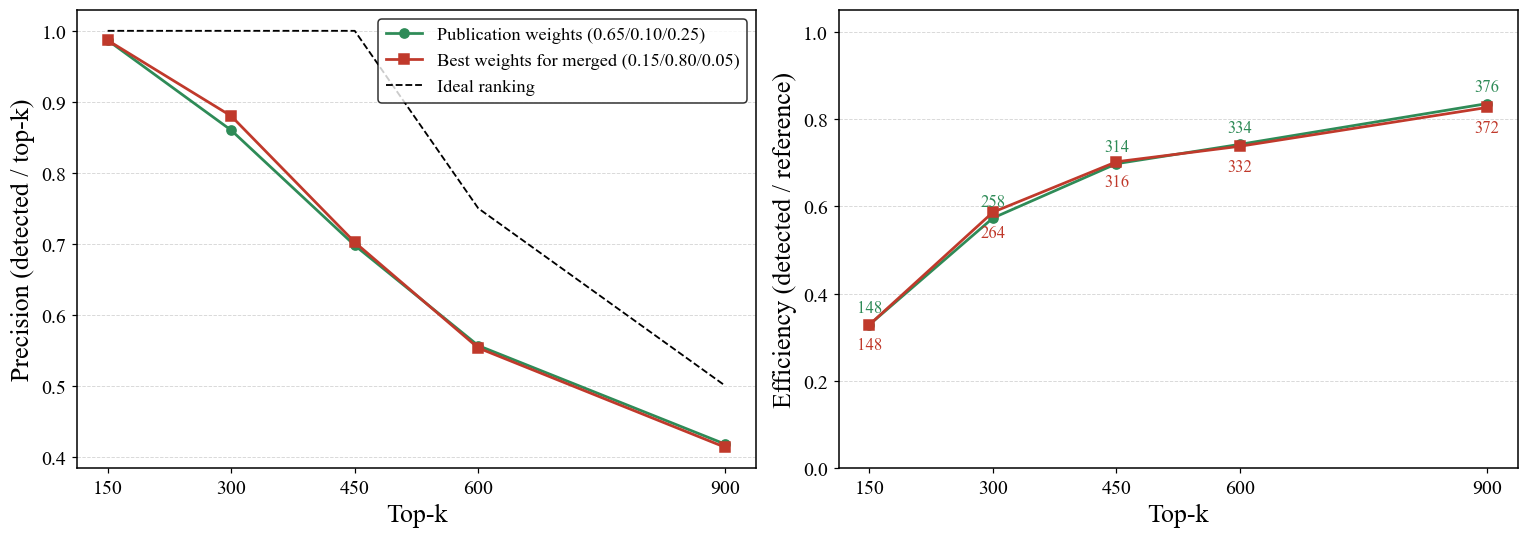

angle_preserving (rekordow referencyjnych: 150); liczby przy punktach = wykryte rekordy


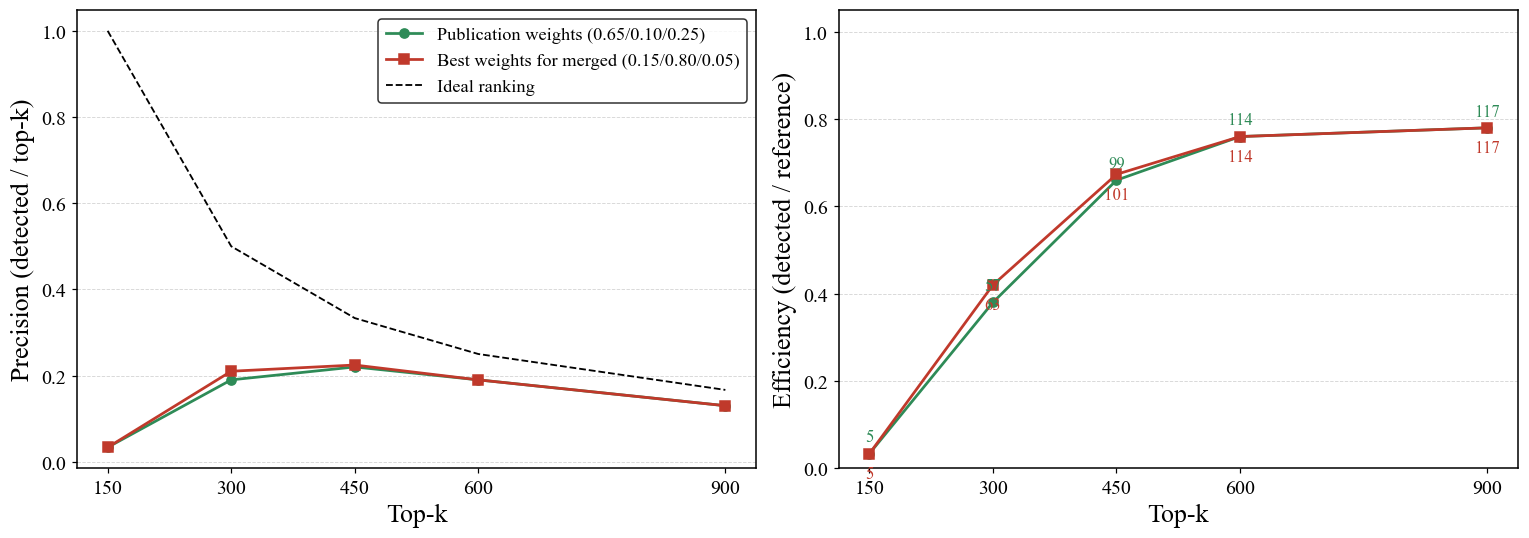

rigid (rekordow referencyjnych: 150); liczby przy punktach = wykryte rekordy


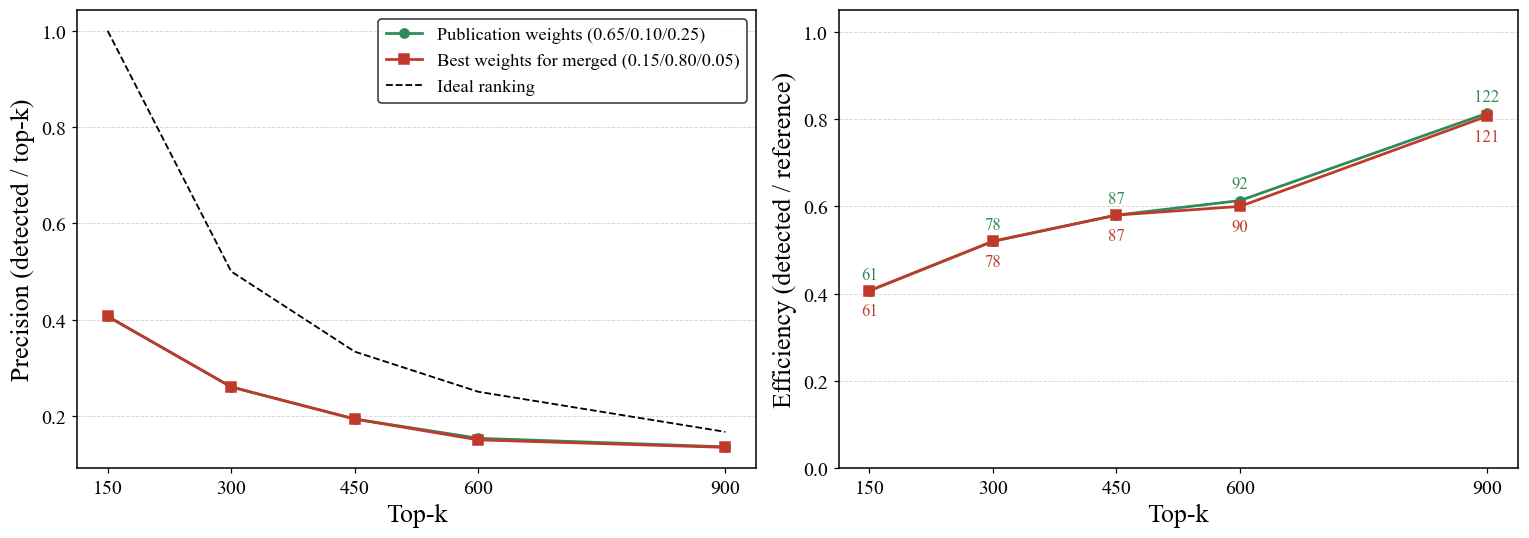

axis_aligned (rekordow referencyjnych: 150); liczby przy punktach = wykryte rekordy


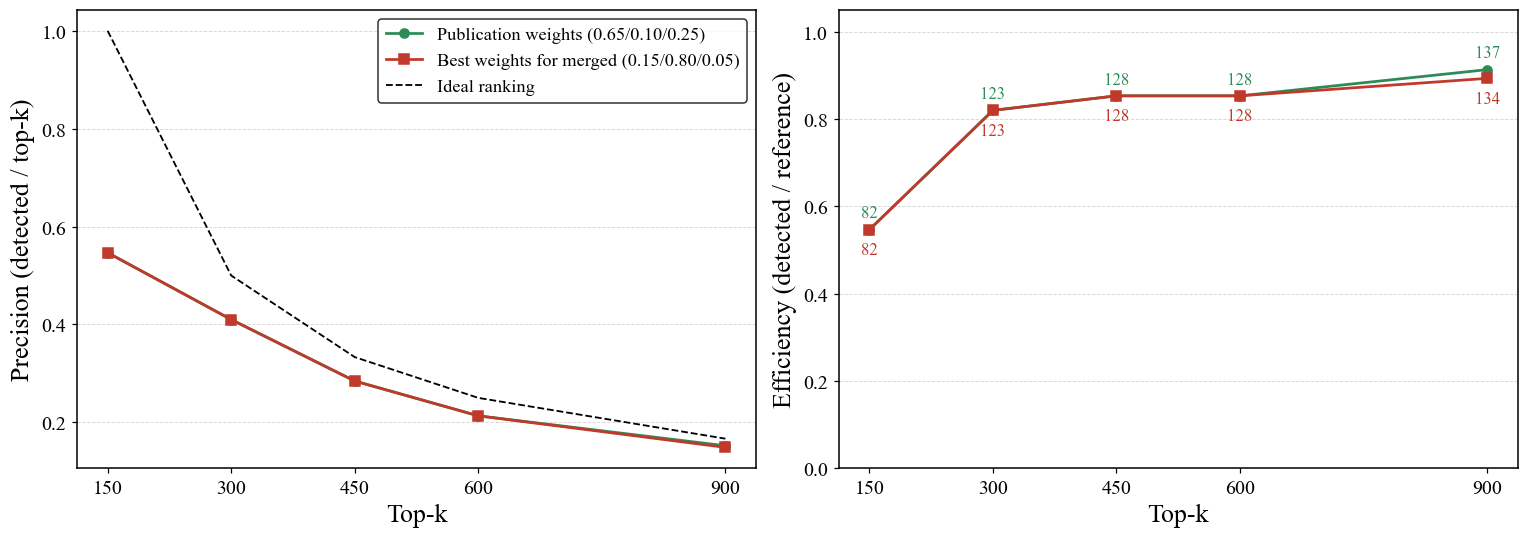

In [10]:
selected_configs = {
    f"Publication weights ({weights_label(PUBLICATION_WEIGHTS)})": (PUBLICATION_WEIGHTS, SERIES["distance"], "o"),
    f"Best weights for merged ({weights_label(BEST_WEIGHTS)})": (BEST_WEIGHTS, SERIES["lbp"], "s"),
}

for report_name in REPORT_ORDER:
    total_reference = int(df[df["report"] == report_name]["total_reference"].iloc[0])
    print(f"{report_name} (rekordow referencyjnych: {total_reference}); liczby przy punktach = wykryte rekordy")
    fig, (ax_precision, ax_recall) = plt.subplots(1, 2, figsize=(14, 5), tight_layout=True)
    for config_index, (config_name, (weights, color, marker)) in enumerate(selected_configs.items()):
        subset = df[(df["report"] == report_name) & (df["weights"] == weights_label(weights))].sort_values("top_k")
        ax_precision.plot(subset["top_k"], subset["precision"], marker=marker, color=color, linewidth=1.8,
                          label=config_name)
        ax_recall.plot(subset["top_k"], subset["recall"], marker=marker, color=color, linewidth=1.8, label=config_name)
        label_offset = 8 if config_index == 0 else -16
        for _, row in subset.iterrows():
            ax_recall.annotate(f"{int(row['matched_top_k'])}", (row["top_k"], row["recall"]),
                               textcoords="offset points", xytext=(0, label_offset), ha="center",
                               fontsize=11, color=color)
    ideal = [min(k, total_reference) / k for k in K_VALUES]
    ax_precision.plot(K_VALUES, ideal, linestyle="--", linewidth=1.2, color="black", label="Ideal ranking")
    for ax in (ax_precision, ax_recall):
        ax.set_xticks(K_VALUES)
    ax_recall.set_ylim(0, 1.05)
    style_axes(ax_precision, "Top-k", "Precision (detected / top-k)")
    style_axes(ax_recall, "Top-k", EFFICIENCY_LABEL)
    style_legend(ax_precision, loc="upper right", fontsize=12)
    plt.show()

## 10. Rozrzut skuteczności po siatce i wnioski

Jak bardzo wagi w ogóle zmieniają wynik? Dla każdego zbioru podajemy min/max/średnią skuteczności (`wykryte / ref.`, top-k = 450) po całej siatce,
liczbę kombinacji w odległości ≤ 1 wykrytego rekordu od maksimum oraz **stabilny obszar wag**
(zakres każdej wagi wśród tych prawie-optymalnych kombinacji).

> **Uwaga o powtarzalności.** Etap `_prepare` nie jest w pełni deterministyczny: model `random_forest`
> w `train_distance_models` nie ma ustawionego `random_state`, a liczba grup embeddingów (LBP) różni się między
> uruchomieniami. Dwa pełne przebiegi tego notebooka z identyczną konfiguracją dały dla wag z publikacji
> 319 i 314 wykrytych w top-450 (notebook źródłowy: 320), a „najlepszy” punkt siatki dla `merged` przesunął się
> z 0.50/0.30/0.20 na 0.15/0.80/0.05 przy różnicy zaledwie 1–2 rekordów względem wag z publikacji.
> Różnice rzędu kilku rekordów między kombinacjami wag należy więc traktować jako szum; wiarygodne są
> **szerokie obszary** (płaskowyż na mapach), nie pojedyncze maksima.

In [11]:
summary_rows = []
for report_name in REPORT_ORDER:
    subset = grid_only[grid_only["report"] == report_name]
    best_matched = int(subset["matched_top_k"].max())
    near_best = subset[subset["matched_top_k"] >= best_matched - 1]
    summary_rows.append(
        {
            "report": report_name,
            "min_recall": subset["recall"].min(),
            "mean_recall": subset["recall"].mean(),
            "max_recall": subset["recall"].max(),
            "min_matched": int(subset["matched_top_k"].min()),
            "max_matched": best_matched,
            "near_best_configs": int(len(near_best)),
            "near_best_distance_w": f"{near_best['distance_w'].min():.2f}-{near_best['distance_w'].max():.2f}",
            "near_best_lbp_w": f"{near_best['lbp_w'].min():.2f}-{near_best['lbp_w'].max():.2f}",
            "near_best_seg_w": f"{near_best['seg_w'].min():.2f}-{near_best['seg_w'].max():.2f}",
        }
    )
summary_df = pd.DataFrame(summary_rows).set_index("report")

print(f"Siatka: {len(grid_only['weights'].unique())} kombinacji wag, top_k = {BASE_TOP_K}\n")
print(summary_df.to_string(float_format=lambda v: f"{v:.3f}"))

merged_grid = grid_only[grid_only["report"] == "merged"]
pure = {
    name: int(merged_grid[merged_grid["weights"] == weights_label(w)]["matched_top_k"].iloc[0])
    for name, w in (("distance", (1.0, 0.0, 0.0)), ("lbp", (0.0, 1.0, 0.0)), ("segmentation", (0.0, 0.0, 1.0)))
}
print("\nWNIOSKI (generowane z danych):")
print(f"- merged: zakres wykrytych w top-{BASE_TOP_K} po siatce: {summary_df.loc['merged', 'min_matched']}"
      f"-{summary_df.loc['merged', 'max_matched']} (skutecznosc {summary_df.loc['merged', 'min_recall']:.3f}"
      f"-{summary_df.loc['merged', 'max_recall']:.3f}).")
print(f"- pojedyncze modele (merged, wykryte/{BASE_TOP_K}): distance={pure['distance']}, lbp={pure['lbp']}, "
      f"segmentation={pure['segmentation']}; najlepsza kombinacja {weights_label(BEST_WEIGHTS)} "
      f"= {int(best_merged['matched_top_k'])}, publikacja {weights_label(PUBLICATION_WEIGHTS)} "
      f"= {int(publication_merged['matched_top_k'])}.")
for report_name in REPORT_ORDER[1:]:
    best = best_per_report[report_name]
    print(f"- {report_name}: max {int(best['matched_top_k'])}/{int(best['total_reference'])} przy wagach {best['weights']} "
          f"(skutecznosc={best['recall']:.3f}); stabilny obszar: distance {summary_df.loc[report_name, 'near_best_distance_w']}, "
          f"lbp {summary_df.loc[report_name, 'near_best_lbp_w']}, seg {summary_df.loc[report_name, 'near_best_seg_w']}.")

Siatka: 231 kombinacji wag, top_k = 450

                  min_recall  mean_recall  max_recall  min_matched  max_matched  near_best_configs near_best_distance_w near_best_lbp_w near_best_seg_w
report                                                                                                                                                 
merged                 0.480        0.661       0.702          216          316                  5            0.15-0.60       0.15-0.80       0.05-0.25
angle_preserving       0.180        0.450       0.707           27          106                 10            0.25-0.80       0.00-0.70       0.05-0.20
rigid                  0.500        0.690       0.833           75          125                 27            0.00-0.05       0.00-0.95       0.05-1.00
axis_aligned           0.687        0.844       0.853          103          128                135            0.05-1.00       0.00-0.95       0.00-0.90

WNIOSKI (generowane z danych):
- merged: zakre